# SafeFundus — Notebook 02: DenseNet121 Backbone Baseline

## Purpose

This notebook trains the first **backbone-screening baseline** for SafeFundus using **DenseNet121**.

The experimental protocol is frozen from the RFMiD dataset analysis:

- **Known diseases:** 14 classes with at least 30 positive RFMiD training examples.
- **Unknown diseases:** rare classes with fewer than 20 positive training examples.
- **Intermediate diseases:** CRVO and RPEC; excluded from the primary experiment.
- **Training:** Normal + Known-only images.
- **Validation:** Normal + Known-only images.
- **Familiar internal test:** Normal + Known-only images.
- **Unknown safety test:** Unknown-only images.
- **Mixed known + unknown:** excluded here; evaluated later as an exploratory SafeFundus experiment.

### Why this notebook exists

At this stage we are **screening backbones**, not yet testing JointEnergy or MC Dropout.

We will later compare:

1. DenseNet121
2. DenseNet121
3. EfficientNet-B0
4. ConvNeXt-Tiny

All backbones must use the same preprocessing, split logic, loss, optimizer, early-stopping metric, and evaluation code.

### Main outputs

This notebook saves:

- best DenseNet121 checkpoint
- training history
- validation-optimized disease thresholds
- familiar-test predictions
- unknown-only predictions
- per-class metrics
- overall classification metrics
- rare-to-normal baseline safety error
- training curves


In [1]:
# ============================================================
# 1. Imports
# ============================================================

from pathlib import Path
import os
import json
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import DenseNet121_Weights
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


# 2. Configuration

For backbone screening we use:

- Image size: **224 × 224**
- ImageNet pretrained DenseNet121
- Weighted binary cross-entropy
- AdamW
- Mixed precision
- Early stopping on validation **mAP**
- Validation-optimized per-class thresholds after training

> **Important:** This is the backbone-screening setup. After choosing the main backbone, the final SafeFundus experiments can compare/refine the loss while keeping the safety modules fair.


In [2]:
# ============================================================
# 2. Configuration
# ============================================================

CONFIG = {
    "seed": 42,
    "image_size": 224,
    "batch_size": 32,
    "epochs": 35,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "dropout": 0.3,
    "num_workers": 2,
    "early_stopping_patience": 7,
    "lr_patience": 3,
    "threshold_grid_start": 0.05,
    "threshold_grid_end": 0.95,
    "threshold_grid_step": 0.01,
    "model_name": "densenet121",
}

DATA_ROOT = Path(
    "/kaggle/input/datasets/ozlemhakdagli/"
    "retinal-fundus-multi-disease-image-dataset-rfmid"
)

TRAIN_DIR = DATA_ROOT / "Training_set"
VAL_DIR   = DATA_ROOT / "Validation_set"
TEST_DIR  = DATA_ROOT / "Test_set"

TRAIN_CSV = TRAIN_DIR / "RFMiD_Training_Labels.csv"
VAL_CSV   = VAL_DIR   / "RFMiD_Validation_Labels.csv"
TEST_CSV  = TEST_DIR  / "RFMiD_Testing_Labels.csv"

OUTPUT_DIR = Path("/kaggle/working/safefundus_densenet121")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
TABLE_DIR = OUTPUT_DIR / "tables"
FIG_DIR = OUTPUT_DIR / "figures"
PRED_DIR = OUTPUT_DIR / "predictions"

for p in [OUTPUT_DIR, CHECKPOINT_DIR, TABLE_DIR, FIG_DIR, PRED_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print(json.dumps(CONFIG, indent=2))
print("\nOutput directory:", OUTPUT_DIR)


{
  "seed": 42,
  "image_size": 224,
  "batch_size": 32,
  "epochs": 35,
  "learning_rate": 0.0001,
  "weight_decay": 0.0001,
  "dropout": 0.3,
  "num_workers": 2,
  "early_stopping_patience": 7,
  "lr_patience": 3,
  "threshold_grid_start": 0.05,
  "threshold_grid_end": 0.95,
  "threshold_grid_step": 0.01,
  "model_name": "densenet121"
}

Output directory: /kaggle/working/safefundus_densenet121


# 3. Reproducibility

We fix the random seed so the initial backbone comparison is reproducible.


In [3]:
# ============================================================
# 3. Reproducibility
# ============================================================

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(CONFIG["seed"])

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)


DEVICE: cuda


# 4. Frozen Known / Unknown Protocol

The 14 known classes selected from the RFMiD training-frequency analysis are:

- DR
- MH
- ODC
- TSLN
- DN
- MYA
- ARMD
- BRVO
- ODP
- ODE
- LS
- RS
- CSR
- CRS

The intermediate classes are:

- CRVO
- RPEC

Every other disease label is treated as a candidate **unknown rare disease** for the open-set protocol.


In [4]:
# ============================================================
# 4. Frozen disease protocol
# ============================================================

KNOWN_CLASSES = [
    "DR", "MH", "ODC", "TSLN", "DN", "MYA", "ARMD",
    "BRVO", "ODP", "ODE", "LS", "RS", "CSR", "CRS"
]

INTERMEDIATE_CLASSES = ["CRVO", "RPEC"]

print("Known classes:", len(KNOWN_CLASSES))
print(KNOWN_CLASSES)
print("\nIntermediate classes:", INTERMEDIATE_CLASSES)


Known classes: 14
['DR', 'MH', 'ODC', 'TSLN', 'DN', 'MYA', 'ARMD', 'BRVO', 'ODP', 'ODE', 'LS', 'RS', 'CSR', 'CRS']

Intermediate classes: ['CRVO', 'RPEC']


# 5. Load RFMiD Labels and Reconstruct the Frozen Image Groups

We recreate the exact image-level grouping from Notebook 00.

### Groups

- **Normal:** no disease labels
- **Known_Only:** at least one known disease and no unknown/intermediate label
- **Unknown_Only:** only held-out unknown disease labels
- **Mixed_Known_Unknown:** both known and unknown labels
- **Contains_Intermediate:** at least one CRVO or RPEC label

Only Normal + Known_Only are used for training and validation.


In [5]:
# ============================================================
# 5. Load labels and construct groups
# ============================================================

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

ID_COL = "ID"
RISK_COL = "Disease_Risk"

assert ID_COL in train_df.columns, f"{ID_COL} column not found."
assert RISK_COL in train_df.columns, f"{RISK_COL} column not found."

DISEASE_COLS = [
    c for c in train_df.columns
    if c not in {ID_COL, RISK_COL}
]

missing_known = [c for c in KNOWN_CLASSES if c not in DISEASE_COLS]
missing_intermediate = [c for c in INTERMEDIATE_CLASSES if c not in DISEASE_COLS]

assert not missing_known, f"Known labels missing from CSV: {missing_known}"
assert not missing_intermediate, f"Intermediate labels missing from CSV: {missing_intermediate}"

UNKNOWN_CLASSES = [
    c for c in DISEASE_COLS
    if c not in KNOWN_CLASSES and c not in INTERMEDIATE_CLASSES
]

print("Total pathology columns:", len(DISEASE_COLS))
print("Known classes:", len(KNOWN_CLASSES))
print("Unknown classes:", len(UNKNOWN_CLASSES))
print("Intermediate classes:", len(INTERMEDIATE_CLASSES))

def assign_group(row):
    positive = {c for c in DISEASE_COLS if int(row[c]) == 1}

    if len(positive) == 0:
        return "Normal"

    if positive & set(INTERMEDIATE_CLASSES):
        return "Contains_Intermediate"

    has_known = bool(positive & set(KNOWN_CLASSES))
    has_unknown = bool(positive & set(UNKNOWN_CLASSES))

    if has_known and has_unknown:
        return "Mixed_Known_Unknown"
    if has_known:
        return "Known_Only"
    if has_unknown:
        return "Unknown_Only"

    return "Other"

for df in [train_df, val_df, test_df]:
    df["Group"] = df.apply(assign_group, axis=1)

def show_group_counts(df, name):
    print(f"\n{name}")
    display(df["Group"].value_counts().rename_axis("Group").reset_index(name="Count"))

show_group_counts(train_df, "TRAIN")
show_group_counts(val_df, "VALIDATION")
show_group_counts(test_df, "TEST")


Total pathology columns: 45
Known classes: 14
Unknown classes: 29
Intermediate classes: 2

TRAIN


,Group,Count
0,Known_Only,1312
1,Normal,401
2,Mixed_Known_Unknown,82
3,Unknown_Only,75
4,Contains_Intermediate,50



VALIDATION


,Group,Count
0,Known_Only,426
1,Normal,134
2,Unknown_Only,34
3,Mixed_Known_Unknown,32
4,Contains_Intermediate,14



TEST


,Group,Count
0,Known_Only,437
1,Normal,134
2,Unknown_Only,32
3,Mixed_Known_Unknown,24
4,Contains_Intermediate,13


# 6. Create the Actual Experimental Splits

### Training

Normal + Known-only.

### Validation

Normal + Known-only.

### Familiar internal test

Normal + Known-only.

This set is used for standard 14-label disease-classification metrics.

### Unknown-only safety test

Unknown-only RFMiD test images.

These images are **not** included in ordinary classification metrics because their 14 known-disease target vector is all zeros. Instead, we use them for the baseline safety question:

> How often does a closed-set model see an unseen rare disease and output no known disease, effectively treating the image as normal?


In [6]:
# ============================================================
# 6. Experimental dataframes
# ============================================================

train_exp = train_df[train_df["Group"].isin(["Normal", "Known_Only"])].copy()
val_exp = val_df[val_df["Group"].isin(["Normal", "Known_Only"])].copy()

test_familiar = test_df[
    test_df["Group"].isin(["Normal", "Known_Only"])
].copy()

test_unknown = test_df[
    test_df["Group"] == "Unknown_Only"
].copy()

test_mixed = test_df[
    test_df["Group"] == "Mixed_Known_Unknown"
].copy()

print("Training images       :", len(train_exp))
print("Validation images     :", len(val_exp))
print("Familiar test images  :", len(test_familiar))
print("Unknown-only test     :", len(test_unknown))
print("Mixed exploratory test:", len(test_mixed))

# Expected from Notebook 00
expected = {
    "train": 1713,
    "val": 560,
    "unknown_test": 32,
    "mixed_test": 24,
}

print("\nProtocol verification:")
print("Train matches expected :", len(train_exp) == expected["train"])
print("Val matches expected   :", len(val_exp) == expected["val"])
print("Unknown matches expected:", len(test_unknown) == expected["unknown_test"])
print("Mixed matches expected :", len(test_mixed) == expected["mixed_test"])


Training images       : 1713
Validation images     : 560
Familiar test images  : 571
Unknown-only test     : 32
Mixed exploratory test: 24

Protocol verification:
Train matches expected : True
Val matches expected   : True
Unknown matches expected: True
Mixed matches expected : True


# 7. Image Paths

RFMiD image files are named using the numeric image ID, for example `123.png`.

We map each CSV row to the correct split folder.


In [7]:
# ============================================================
# 7. Add image paths
# ============================================================

def normalize_id(x):
    return str(int(float(x)))

def add_image_paths(df, folder):
    out = df.copy()
    out["image_path"] = out[ID_COL].apply(
        lambda x: str(folder / f"{normalize_id(x)}.png")
    )

    missing = [p for p in out["image_path"] if not Path(p).exists()]
    if missing:
        raise FileNotFoundError(
            f"{len(missing)} image files are missing. Example: {missing[:3]}"
        )

    return out

train_exp = add_image_paths(train_exp, TRAIN_DIR)
val_exp = add_image_paths(val_exp, VAL_DIR)
test_familiar = add_image_paths(test_familiar, TEST_DIR)
test_unknown = add_image_paths(test_unknown, TEST_DIR)
test_mixed = add_image_paths(test_mixed, TEST_DIR)

print("All image paths verified.")


All image paths verified.


# 8. Preprocessing and Augmentation

We keep augmentation mild because retinal lesions can be small.

### Training

- resize to 224 × 224
- horizontal flip
- small rotation
- mild brightness / contrast / saturation changes
- ImageNet normalization

### Validation / Test

- resize
- ImageNet normalization

The same transforms should later be used for the other backbone-screening notebooks.


In [8]:
# ============================================================
# 8. Transforms
# ============================================================

weights = DenseNet121_Weights.IMAGENET1K_V1
imagenet_mean = weights.transforms().mean
imagenet_std = weights.transforms().std

train_transform = transforms.Compose([
    transforms.Resize((CONFIG["image_size"], CONFIG["image_size"])),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.08,
        hue=0.02,
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])

eval_transform = transforms.Compose([
    transforms.Resize((CONFIG["image_size"], CONFIG["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])

print("ImageNet mean:", imagenet_mean)
print("ImageNet std :", imagenet_std)


ImageNet mean: [0.485, 0.456, 0.406]
ImageNet std : [0.229, 0.224, 0.225]


# 9. PyTorch Dataset

The target is a 14-dimensional multi-hot vector.

Example:

`[1, 0, 0, 0, 1, ...]`

means that more than one known retinal disease may be present.


In [9]:
# ============================================================
# 9. Dataset
# ============================================================

class RFMiDDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row["image_path"]).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        target = torch.tensor(
            row[KNOWN_CLASSES].astype(np.float32).values,
            dtype=torch.float32
        )

        return {
            "image": image,
            "target": target,
            "id": normalize_id(row[ID_COL]),
            "group": row["Group"],
        }

train_dataset = RFMiDDataset(train_exp, train_transform)
val_dataset = RFMiDDataset(val_exp, eval_transform)
test_familiar_dataset = RFMiDDataset(test_familiar, eval_transform)
test_unknown_dataset = RFMiDDataset(test_unknown, eval_transform)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Familiar test:", len(test_familiar_dataset))
print("Unknown test:", len(test_unknown_dataset))


Train dataset: 1713
Validation dataset: 560
Familiar test: 571
Unknown test: 32


In [10]:
# ============================================================
# 10. DataLoaders
# ============================================================

def seed_worker(worker_id):
    worker_seed = CONFIG["seed"] + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)

generator = torch.Generator()
generator.manual_seed(CONFIG["seed"])

train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    pin_memory=True,
    persistent_workers=CONFIG["num_workers"] > 0,
    worker_init_fn=seed_worker,
    generator=generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=True,
    persistent_workers=CONFIG["num_workers"] > 0,
)

test_familiar_loader = DataLoader(
    test_familiar_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=True,
    persistent_workers=CONFIG["num_workers"] > 0,
)

test_unknown_loader = DataLoader(
    test_unknown_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=True,
    persistent_workers=CONFIG["num_workers"] > 0,
)

batch = next(iter(train_loader))
print("Image batch shape :", batch["image"].shape)
print("Target batch shape:", batch["target"].shape)


Image batch shape : torch.Size([32, 3, 224, 224])
Target batch shape: torch.Size([32, 14])


# 11. Class Imbalance and Weighted BCE

For known class \(c\):

\[
\text{pos\_weight}_c =
\frac{N_{\text{negative},c}}
{N_{\text{positive},c}}
\]

This increases the loss contribution of rare positive labels.

We cap the weight at 20 to prevent a small class from dominating optimization.


In [11]:
# ============================================================
# 11. Calculate positive class weights
# ============================================================

positive_counts = train_exp[KNOWN_CLASSES].sum(axis=0).astype(float)
negative_counts = len(train_exp) - positive_counts

pos_weight = negative_counts / np.maximum(positive_counts, 1.0)
pos_weight = np.minimum(pos_weight, 20.0)

class_balance_df = pd.DataFrame({
    "Disease": KNOWN_CLASSES,
    "Positive_Train": positive_counts.values.astype(int),
    "Negative_Train": negative_counts.values.astype(int),
    "Pos_Weight": pos_weight.values,
})

display(class_balance_df)

class_balance_df.to_csv(
    TABLE_DIR / "densenet121_class_balance.csv",
    index=False
)

POS_WEIGHT_TENSOR = torch.tensor(
    pos_weight.values,
    dtype=torch.float32,
    device=DEVICE
)


,Disease,Positive_Train,Negative_Train,Pos_Weight
0,DR,358,1355,3.784916
1,MH,306,1407,4.598039
2,ODC,261,1452,5.563218
3,TSLN,174,1539,8.844828
4,DN,126,1587,12.595238
5,MYA,99,1614,16.303030
6,ARMD,92,1621,17.619565
7,BRVO,71,1642,20.000000
8,ODP,52,1661,20.000000
9,ODE,53,1660,20.000000


# 12. Build DenseNet121

We use ImageNet-pretrained DenseNet121 and replace the final classification layer with:

- dropout
- 14-output linear layer

The model returns **raw logits**. Sigmoid is applied only for metrics/inference.


In [12]:
# ============================================================
# 12. Model
# ============================================================

def build_densenet121(num_classes, dropout=0.3):
    try:
        model = models.densenet121(
            weights=DenseNet121_Weights.IMAGENET1K_V1
        )
        print("Loaded ImageNet pretrained DenseNet121 weights.")
    except Exception as e:
        print("WARNING: Could not load pretrained weights.")
        print("Reason:", e)
        print(
            "\nFor the real experiment, enable Kaggle Internet or provide "
            "the pretrained weights. Training from scratch is NOT recommended."
        )
        model = models.densenet121(weights=None)

    in_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(p=dropout),
        nn.Linear(in_features, num_classes)
    )

    return model

model = build_densenet121(
    num_classes=len(KNOWN_CLASSES),
    dropout=CONFIG["dropout"],
).to(DEVICE)

print(model.classifier)


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 213MB/s]


Loaded ImageNet pretrained DenseNet121 weights.
Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1024, out_features=14, bias=True)
)


# 13. Loss, Optimizer, Scheduler

Early stopping uses **validation mean average precision (mAP)**.

Why mAP?

- It is well suited to multi-label classification.
- It does not depend on a fixed classification threshold.
- It is more informative than plain accuracy for imbalanced labels.


In [13]:
# ============================================================
# 13. Training components
# ============================================================

criterion = nn.BCEWithLogitsLoss(
    pos_weight=POS_WEIGHT_TENSOR
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"],
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=CONFIG["lr_patience"],
)

scaler = torch.cuda.amp.GradScaler(
    enabled=(DEVICE.type == "cuda")
)

print("Loss      : BCEWithLogitsLoss + pos_weight")
print("Optimizer : AdamW")
print("Scheduler : ReduceLROnPlateau on validation mAP")
print("AMP       :", DEVICE.type == "cuda")


Loss      : BCEWithLogitsLoss + pos_weight
Optimizer : AdamW
Scheduler : ReduceLROnPlateau on validation mAP
AMP       : True


# 14. Metric Functions

During training:

- probabilities are obtained with sigmoid;
- mAP and Macro AUROC are calculated without threshold tuning;
- F1 during training uses a temporary threshold of 0.5.

After the best model is selected, the final disease thresholds are optimized **only on validation data**.


In [14]:
# ============================================================
# 14. Metrics
# ============================================================

def safe_macro_auroc(y_true, y_prob):
    scores = []

    for c in range(y_true.shape[1]):
        if len(np.unique(y_true[:, c])) < 2:
            continue

        scores.append(
            roc_auc_score(y_true[:, c], y_prob[:, c])
        )

    return float(np.mean(scores)) if scores else np.nan

def safe_map(y_true, y_prob):
    scores = []

    for c in range(y_true.shape[1]):
        if y_true[:, c].sum() == 0:
            continue

        scores.append(
            average_precision_score(y_true[:, c], y_prob[:, c])
        )

    return float(np.mean(scores)) if scores else np.nan

def compute_epoch_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)

    return {
        "macro_f1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "micro_f1": f1_score(
            y_true, y_pred,
            average="micro",
            zero_division=0
        ),
        "mAP": safe_map(y_true, y_prob),
        "macro_auroc": safe_macro_auroc(y_true, y_prob),
    }


# 15. Training and Validation Loops


In [15]:
# ============================================================
# 15. Train / validation functions
# ============================================================

def train_one_epoch(model, loader, optimizer, criterion, scaler):
    model.train()

    running_loss = 0.0
    all_targets = []
    all_probs = []

    pbar = tqdm(loader, desc="Train", leave=False)

    for batch in pbar:
        images = batch["image"].to(DEVICE, non_blocking=True)
        targets = batch["target"].to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(
            enabled=(DEVICE.type == "cuda")
        ):
            logits = model(images)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        probs = torch.sigmoid(logits)

        running_loss += loss.item() * images.size(0)
        all_targets.append(targets.detach().cpu().numpy())
        all_probs.append(probs.detach().cpu().numpy())

        pbar.set_postfix(loss=f"{loss.item():.4f}")

    y_true = np.concatenate(all_targets)
    y_prob = np.concatenate(all_probs)

    metrics = compute_epoch_metrics(y_true, y_prob)
    metrics["loss"] = running_loss / len(loader.dataset)

    return metrics

@torch.no_grad()
def evaluate_loader(model, loader, criterion=None):
    model.eval()

    running_loss = 0.0
    all_targets = []
    all_probs = []
    all_logits = []
    all_ids = []
    all_groups = []

    for batch in tqdm(loader, desc="Evaluate", leave=False):
        images = batch["image"].to(DEVICE, non_blocking=True)
        targets = batch["target"].to(DEVICE, non_blocking=True)

        with torch.cuda.amp.autocast(
            enabled=(DEVICE.type == "cuda")
        ):
            logits = model(images)

            if criterion is not None:
                loss = criterion(logits, targets)
                running_loss += loss.item() * images.size(0)

        probs = torch.sigmoid(logits)

        all_targets.append(targets.cpu().numpy())
        all_probs.append(probs.cpu().numpy())
        all_logits.append(logits.cpu().numpy())
        all_ids.extend(batch["id"])
        all_groups.extend(batch["group"])

    y_true = np.concatenate(all_targets)
    y_prob = np.concatenate(all_probs)
    logits = np.concatenate(all_logits)

    metrics = compute_epoch_metrics(y_true, y_prob)

    if criterion is not None:
        metrics["loss"] = running_loss / len(loader.dataset)

    return {
        "metrics": metrics,
        "targets": y_true,
        "probs": y_prob,
        "logits": logits,
        "ids": all_ids,
        "groups": all_groups,
    }


# 16. Train DenseNet121

The best checkpoint is selected by **validation mAP**.

The notebook uses early stopping to avoid unnecessary Kaggle GPU time.


In [16]:
# ============================================================
# 16. Training
# ============================================================

history = []

best_val_map = -np.inf
epochs_without_improvement = 0

best_checkpoint_path = CHECKPOINT_DIR / "best_densenet121_rfmid.pth"

start_time = time.time()

for epoch in range(1, CONFIG["epochs"] + 1):

    print(f"\n{'='*70}")
    print(f"Epoch {epoch}/{CONFIG['epochs']}")
    print(f"{'='*70}")

    train_metrics = train_one_epoch(
        model, train_loader, optimizer, criterion, scaler
    )

    val_result = evaluate_loader(
        model, val_loader, criterion
    )
    val_metrics = val_result["metrics"]

    scheduler.step(val_metrics["mAP"])

    current_lr = optimizer.param_groups[0]["lr"]

    row = {
        "epoch": epoch,
        "lr": current_lr,

        "train_loss": train_metrics["loss"],
        "train_macro_f1": train_metrics["macro_f1"],
        "train_micro_f1": train_metrics["micro_f1"],
        "train_mAP": train_metrics["mAP"],
        "train_macro_auroc": train_metrics["macro_auroc"],

        "val_loss": val_metrics["loss"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_micro_f1": val_metrics["micro_f1"],
        "val_mAP": val_metrics["mAP"],
        "val_macro_auroc": val_metrics["macro_auroc"],
    }

    history.append(row)

    print(
        f"Train Loss={train_metrics['loss']:.4f} | "
        f"mAP={train_metrics['mAP']:.4f} | "
        f"Macro-F1={train_metrics['macro_f1']:.4f}"
    )

    print(
        f"Val   Loss={val_metrics['loss']:.4f} | "
        f"mAP={val_metrics['mAP']:.4f} | "
        f"Macro-F1={val_metrics['macro_f1']:.4f} | "
        f"AUROC={val_metrics['macro_auroc']:.4f}"
    )

    print(f"LR={current_lr:.2e}")

    if val_metrics["mAP"] > best_val_map:
        best_val_map = val_metrics["mAP"]
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "config": CONFIG,
            "known_classes": KNOWN_CLASSES,
            "best_val_map": best_val_map,
            "epoch": epoch,
        }, best_checkpoint_path)

        print(f"✓ New best checkpoint saved: val mAP={best_val_map:.4f}")

    else:
        epochs_without_improvement += 1

        print(
            "No validation mAP improvement for "
            f"{epochs_without_improvement} epoch(s)."
        )

    if epochs_without_improvement >= CONFIG["early_stopping_patience"]:
        print("\nEarly stopping triggered.")
        break

elapsed_minutes = (time.time() - start_time) / 60

print(f"\nTraining finished in {elapsed_minutes:.1f} minutes.")
print("Best validation mAP:", best_val_map)
print("Best checkpoint:", best_checkpoint_path)

history_df = pd.DataFrame(history)
history_df.to_csv(
    TABLE_DIR / "densenet121_training_history.csv",
    index=False
)

display(history_df.tail())



Epoch 1/35


Train:   0%|          | 0/54 [00:07<?, ?it/s]

Evaluate:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss=0.9713 | mAP=0.2229 | Macro-F1=0.2168
Val   Loss=0.8121 | mAP=0.4157 | Macro-F1=0.3476 | AUROC=0.8500
LR=1.00e-04
✓ New best checkpoint saved: val mAP=0.4157

Epoch 2/35


Train:   0%|          | 0/54 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/18 [00:00<?, ?it/s]

... (79 outputs left out)

Train:   0%|          | 0/54 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss=0.0500 | mAP=0.9984 | Macro-F1=0.9683
Val   Loss=0.7335 | mAP=0.6838 | Macro-F1=0.6546 | AUROC=0.9384
LR=2.50e-05
No validation mAP improvement for 7 epoch(s).

Early stopping triggered.

Training finished in 83.0 minutes.
Best validation mAP: 0.7158356582373026
Best checkpoint: /kaggle/working/safefundus_densenet121/checkpoints/best_densenet121_rfmid.pth


,epoch,lr,train_loss,train_macro_f1,train_micro_f1,train_mAP,train_macro_auroc,val_loss,val_macro_f1,val_micro_f1,val_mAP,val_macro_auroc
24,25,0.000050,0.065151,0.953234,0.945864,0.996200,0.999317,0.720984,0.624117,0.675453,0.677126,0.933305
25,26,0.000025,0.056987,0.964471,0.954746,0.997039,0.999550,0.745546,0.616388,0.683047,0.679317,0.934104
26,27,0.000025,0.053091,0.970452,0.962531,0.998199,0.999784,0.733209,0.646919,0.689019,0.682059,0.937068
27,28,0.000025,0.054322,0.969381,0.962591,0.997749,0.999665,0.705697,0.648391,0.689712,0.693395,0.937972
28,29,0.000025,0.049977,0.968269,0.965671,0.998401,0.999805,0.733454,0.654594,0.694468,0.683765,0.938445


# 17. Training Curves


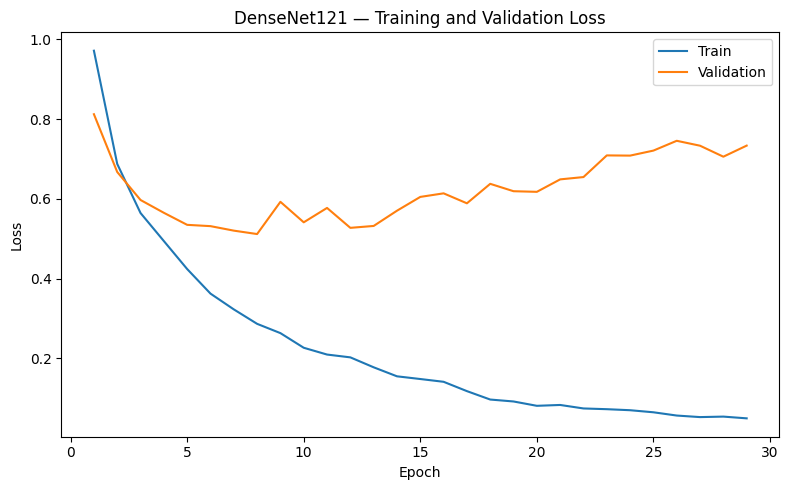

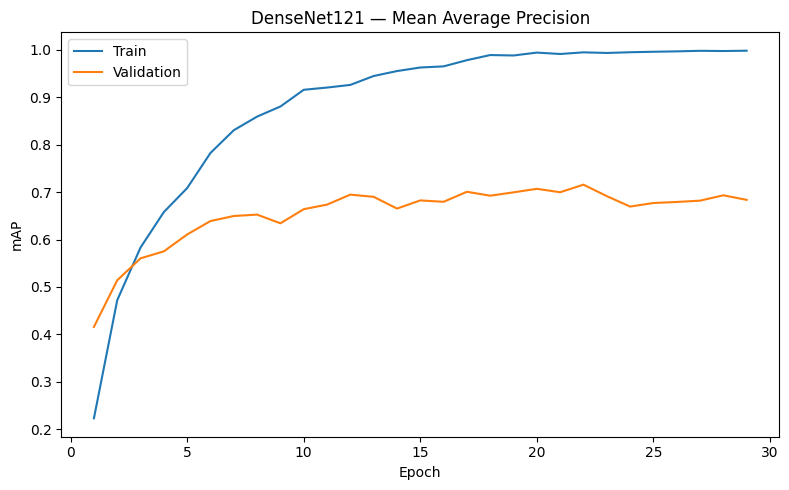

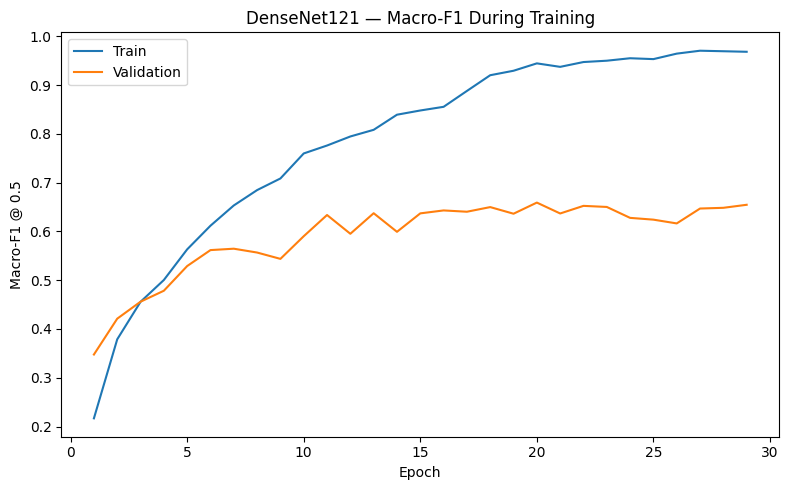

In [17]:
# ============================================================
# 17. Plot training history
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DenseNet121 — Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "densenet121_loss_curve.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_mAP"], label="Train")
plt.plot(history_df["epoch"], history_df["val_mAP"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("DenseNet121 — Mean Average Precision")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "densenet121_map_curve.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_macro_f1"], label="Train")
plt.plot(history_df["epoch"], history_df["val_macro_f1"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Macro-F1 @ 0.5")
plt.title("DenseNet121 — Macro-F1 During Training")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "densenet121_macro_f1_curve.png", dpi=200, bbox_inches="tight")
plt.show()


# 18. Load the Best Checkpoint

Everything below uses the best validation-mAP model, not the final epoch.


In [18]:
# ============================================================
# 18. Load best model
# ============================================================

checkpoint = torch.load(
    best_checkpoint_path,
    map_location=DEVICE
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Loaded checkpoint from epoch:", checkpoint["epoch"])
print("Best validation mAP:", checkpoint["best_val_map"])


Loaded checkpoint from epoch: 22
Best validation mAP: 0.7158356582373026


# 19. Optimize Per-Class Thresholds on Validation Data Only

For each known disease \(c\):

\[
\tau_c =
\arg\max_{\tau} F1_c(\tau)
\]

No test labels are used to select thresholds.


In [19]:
# ============================================================
# 19. Threshold optimization
# ============================================================

val_result = evaluate_loader(model, val_loader)

val_true = val_result["targets"]
val_prob = val_result["probs"]

threshold_grid = np.arange(
    CONFIG["threshold_grid_start"],
    CONFIG["threshold_grid_end"] + 1e-9,
    CONFIG["threshold_grid_step"],
)

def optimize_thresholds(y_true, y_prob):
    thresholds = []

    for c, disease in enumerate(KNOWN_CLASSES):
        best_threshold = 0.5
        best_f1 = -1.0

        # If no positive validation sample exists, keep 0.5.
        if y_true[:, c].sum() == 0:
            thresholds.append(best_threshold)
            continue

        for threshold in threshold_grid:
            pred = (y_prob[:, c] >= threshold).astype(int)

            score = f1_score(
                y_true[:, c],
                pred,
                zero_division=0
            )

            if score > best_f1:
                best_f1 = score
                best_threshold = float(threshold)

        thresholds.append(best_threshold)

    return np.array(thresholds, dtype=np.float32)

CLASS_THRESHOLDS = optimize_thresholds(
    val_true,
    val_prob
)

threshold_df = pd.DataFrame({
    "Disease": KNOWN_CLASSES,
    "Threshold": CLASS_THRESHOLDS,
})

display(threshold_df)

threshold_df.to_csv(
    TABLE_DIR / "densenet121_validation_thresholds.csv",
    index=False
)


Evaluate:   0%|          | 0/18 [00:00<?, ?it/s]

,Disease,Threshold
0,DR,0.72
1,MH,0.52
2,ODC,0.26
3,TSLN,0.58
4,DN,0.39
5,MYA,0.71
6,ARMD,0.48
7,BRVO,0.63
8,ODP,0.36
9,ODE,0.87


# 20. Familiar Test Evaluation

This is the standard 14-label classification evaluation on:

- Normal RFMiD test images
- Known-only RFMiD test images

Unknown-only samples are evaluated separately.


In [20]:
# ============================================================
# 20. Familiar-test evaluation
# ============================================================

familiar_result = evaluate_loader(
    model,
    test_familiar_loader
)

y_true = familiar_result["targets"]
y_prob = familiar_result["probs"]
y_pred = (y_prob >= CLASS_THRESHOLDS[None, :]).astype(int)

overall_metrics = {
    "model": "DenseNet121",
    "seed": CONFIG["seed"],
    "familiar_test_images": int(len(y_true)),
    "macro_f1": float(
        f1_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "micro_f1": float(
        f1_score(y_true, y_pred, average="micro", zero_division=0)
    ),
    "mAP": safe_map(y_true, y_prob),
    "macro_auroc": safe_macro_auroc(y_true, y_prob),
}

print(json.dumps(overall_metrics, indent=2))

with open(TABLE_DIR / "densenet121_overall_metrics.json", "w") as f:
    json.dump(overall_metrics, f, indent=2)


Evaluate:   0%|          | 0/18 [00:00<?, ?it/s]

{
  "model": "DenseNet121",
  "seed": 42,
  "familiar_test_images": 571,
  "macro_f1": 0.639305304516465,
  "micro_f1": 0.6775300171526587,
  "mAP": 0.7248207757675837,
  "macro_auroc": 0.9340105697679039
}


# 21. Per-Disease Metrics

For every known disease we report:

- number of positives
- precision
- sensitivity / recall
- specificity
- F1
- AUROC
- average precision
- selected threshold


In [21]:
# ============================================================
# 21. Per-class metrics
# ============================================================

rows = []

for c, disease in enumerate(KNOWN_CLASSES):

    yt = y_true[:, c]
    yp = y_pred[:, c]
    prob = y_prob[:, c]

    tn, fp, fn, tp = confusion_matrix(
        yt,
        yp,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    auroc = (
        roc_auc_score(yt, prob)
        if len(np.unique(yt)) == 2
        else np.nan
    )

    ap = (
        average_precision_score(yt, prob)
        if yt.sum() > 0
        else np.nan
    )

    rows.append({
        "Disease": disease,
        "Positive_Test": int(yt.sum()),
        "Threshold": float(CLASS_THRESHOLDS[c]),
        "Precision": precision_score(yt, yp, zero_division=0),
        "Sensitivity_Recall": recall_score(yt, yp, zero_division=0),
        "Specificity": specificity,
        "F1": f1_score(yt, yp, zero_division=0),
        "AUROC": auroc,
        "Average_Precision": ap,
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
    })

per_class_metrics = pd.DataFrame(rows)

display(per_class_metrics)

per_class_metrics.to_csv(
    TABLE_DIR / "densenet121_per_class_metrics.csv",
    index=False
)


,Disease,Positive_Test,Threshold,Precision,Sensitivity_Recall,Specificity,F1,AUROC,Average_Precision,TP,FP,TN,FN
0,DR,122,0.72,0.841667,0.827869,0.957684,0.834711,0.977226,0.924724,101,19,430,21
1,MH,100,0.52,0.737705,0.900000,0.932059,0.810811,0.978715,0.923466,90,32,439,10
2,ODC,84,0.26,0.523256,0.535714,0.915811,0.529412,0.840752,0.582114,45,41,446,39
3,TSLN,49,0.58,0.530303,0.714286,0.940613,0.608696,0.956251,0.628745,35,31,491,14
4,DN,45,0.39,0.327273,0.400000,0.929658,0.360000,0.770807,0.338048,18,37,489,27
5,MYA,29,0.71,0.862069,0.862069,0.992620,0.862069,0.990775,0.936699,25,4,538,4
6,ARMD,27,0.48,0.656250,0.777778,0.979779,0.711864,0.978894,0.824244,21,11,533,6
7,BRVO,23,0.63,1.000000,0.739130,1.000000,0.850000,0.917923,0.812022,17,0,548,6
8,ODP,22,0.36,0.272727,0.409091,0.956284,0.327273,0.840950,0.417982,9,24,525,13
9,ODE,16,0.87,1.000000,0.812500,1.000000,0.896552,0.976295,0.892218,13,0,555,3


# 22. Save Familiar-Test Predictions

We save raw logits, sigmoid probabilities, binary predictions, true labels, and image group.

These files will later be useful for:

- backbone comparison
- calibration
- JointEnergy
- error analysis


In [22]:
# ============================================================
# 22. Save familiar-test predictions
# ============================================================

pred_df = pd.DataFrame({
    "ID": familiar_result["ids"],
    "Group": familiar_result["groups"],
})

for c, disease in enumerate(KNOWN_CLASSES):
    pred_df[f"true_{disease}"] = y_true[:, c].astype(int)
    pred_df[f"logit_{disease}"] = familiar_result["logits"][:, c]
    pred_df[f"prob_{disease}"] = y_prob[:, c]
    pred_df[f"pred_{disease}"] = y_pred[:, c].astype(int)

pred_df.to_csv(
    PRED_DIR / "densenet121_familiar_test_predictions.csv",
    index=False
)

display(pred_df.head())


,ID,Group,true_DR,logit_DR,prob_DR,pred_DR,true_MH,logit_MH,prob_MH,pred_MH,...,prob_RS,pred_RS,true_CSR,logit_CSR,prob_CSR,pred_CSR,true_CRS,logit_CRS,prob_CRS,pred_CRS
0,1,Known_Only,1,6.265625,0.998047,1,0,-2.460938,0.078613,0,...,0.001623,0,0,-6.761719,0.001156,0,0,-5.527344,0.003960,0
1,2,Known_Only,1,-2.089844,0.110107,0,0,-5.820312,0.002958,0,...,0.012672,0,0,-5.039062,0.006439,0,0,-3.519531,0.028763,0
2,3,Known_Only,1,-2.244141,0.095886,0,0,-2.041016,0.114990,0,...,0.002157,0,0,-5.664062,0.003456,0,0,-4.035156,0.017380,0
3,9,Known_Only,1,1.660156,0.840332,1,0,-1.863281,0.134277,0,...,0.006588,0,0,-5.664062,0.003456,0,0,-4.441406,0.011642,0
4,10,Known_Only,1,6.457031,0.998535,1,0,-5.019531,0.006565,0,...,0.001549,0,0,-6.007812,0.002453,0,0,-4.656250,0.009415,0


# 23. Closed-Set Baseline Safety Test on Unknown Rare Diseases

Now we intentionally show the trained **closed-set** classifier rare-disease images it never saw during training.

For each unknown-only image:

- if no known disease exceeds its validation threshold, the closed-set system effectively outputs **normal**;
- this becomes a **rare-to-normal error**.

\[
\text{Rare-to-Normal Error Rate}
=
\frac{\text{Unknown-only images with no known disease predicted}}
{\text{Total unknown-only images}}
\]

A high value strengthens the motivation for SafeFundus referral.


In [23]:
# ============================================================
# 23. Unknown-only safety evaluation
# ============================================================

unknown_result = evaluate_loader(
    model,
    test_unknown_loader
)

unknown_prob = unknown_result["probs"]
unknown_pred = (
    unknown_prob >= CLASS_THRESHOLDS[None, :]
).astype(int)

# No known disease predicted = closed-set system would report normal
unknown_predicted_normal = (
    unknown_pred.sum(axis=1) == 0
)

rare_to_normal_count = int(
    unknown_predicted_normal.sum()
)

rare_to_normal_rate = float(
    unknown_predicted_normal.mean()
)

at_least_one_known_prediction_rate = float(
    (~unknown_predicted_normal).mean()
)

safety_metrics = {
    "model": "DenseNet121",
    "unknown_only_test_images": int(len(unknown_pred)),
    "rare_to_normal_count": rare_to_normal_count,
    "rare_to_normal_error_rate": rare_to_normal_rate,
    "unknown_forced_into_known_rate": at_least_one_known_prediction_rate,
}

print(json.dumps(safety_metrics, indent=2))

with open(TABLE_DIR / "densenet121_unknown_safety_metrics.json", "w") as f:
    json.dump(safety_metrics, f, indent=2)


Evaluate:   0%|          | 0/1 [00:00<?, ?it/s]

{
  "model": "DenseNet121",
  "unknown_only_test_images": 32,
  "rare_to_normal_count": 9,
  "rare_to_normal_error_rate": 0.28125,
  "unknown_forced_into_known_rate": 0.71875
}


# 24. Save Unknown-Only Predictions

This table is especially important later when we compare:

- closed-set baseline
- confidence rejection
- MC Dropout
- JointEnergy
- full SafeFundus


In [24]:
# ============================================================
# 24. Save unknown-only predictions
# ============================================================

unknown_pred_df = pd.DataFrame({
    "ID": unknown_result["ids"],
    "Group": unknown_result["groups"],
    "Predicted_Normal": unknown_predicted_normal.astype(int),
    "Num_Known_Diseases_Predicted": unknown_pred.sum(axis=1).astype(int),
    "Max_Known_Probability": unknown_prob.max(axis=1),
})

for c, disease in enumerate(KNOWN_CLASSES):
    unknown_pred_df[f"logit_{disease}"] = unknown_result["logits"][:, c]
    unknown_pred_df[f"prob_{disease}"] = unknown_prob[:, c]
    unknown_pred_df[f"pred_{disease}"] = unknown_pred[:, c].astype(int)

unknown_pred_df.to_csv(
    PRED_DIR / "densenet121_unknown_test_predictions.csv",
    index=False
)

display(
    unknown_pred_df.sort_values(
        "Max_Known_Probability",
        ascending=False
    ).head(10)
)


,ID,Group,Predicted_Normal,Num_Known_Diseases_Predicted,Max_Known_Probability,logit_DR,prob_DR,pred_DR,logit_MH,prob_MH,...,pred_LS,logit_RS,prob_RS,pred_RS,logit_CSR,prob_CSR,pred_CSR,logit_CRS,prob_CRS,pred_CRS
14,150,Unknown_Only,0,1,0.999512,-3.843750,0.020966,0,7.605469,0.999512,...,0,-4.128906,0.015839,0,-5.214844,0.005405,0,-5.023438,0.006538,0
0,4,Unknown_Only,0,1,0.998047,-3.832031,0.021210,0,-5.636719,0.003551,...,0,-3.406250,0.032104,0,-4.882812,0.007519,0,-3.320312,0.034882,0
15,208,Unknown_Only,0,1,0.993652,-1.312500,0.212036,0,-1.817383,0.139771,...,0,-5.031250,0.006489,0,-6.902344,0.001004,0,-3.998047,0.018021,0
6,13,Unknown_Only,0,1,0.987793,-5.070312,0.006241,0,-3.490234,0.029587,...,0,-5.144531,0.005798,0,-2.634766,0.066956,0,-5.144531,0.005798,0
12,58,Unknown_Only,0,1,0.980469,-4.988281,0.006771,0,-2.158203,0.103577,...,0,-3.720703,0.023651,0,-3.810547,0.021652,0,-2.669922,0.064758,0
25,486,Unknown_Only,0,1,0.978027,-3.935547,0.019165,0,-4.214844,0.014557,...,0,3.798828,0.978027,1,-4.746094,0.008614,0,-4.183594,0.015015,0
17,211,Unknown_Only,0,2,0.977539,-5.218750,0.005386,0,-4.863281,0.007668,...,0,-5.308594,0.004925,0,-5.785156,0.003063,0,-3.931641,0.019241,0
3,7,Unknown_Only,0,1,0.976074,-4.457031,0.011467,0,-5.019531,0.006565,...,0,-2.703125,0.062805,0,-3.113281,0.042572,0,-2.205078,0.099304,0
9,26,Unknown_Only,0,1,0.976074,3.703125,0.976074,1,-0.454590,0.388184,...,0,-4.472656,0.011292,0,-4.875000,0.007576,0,-3.923828,0.019379,0
11,50,Unknown_Only,0,4,0.954590,-1.607422,0.166992,0,-2.908203,0.051758,...,0,-5.707031,0.003311,0,-4.988281,0.006771,0,-2.996094,0.047607,0


# 25. Baseline Summary

This cell prints the numbers we need to send back for backbone comparison.


In [25]:
# ============================================================
# 25. Final summary
# ============================================================

summary = {
    **overall_metrics,
    **safety_metrics,
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_mAP": float(checkpoint["best_val_map"]),
}

print("=" * 70)
print("RESNET50 BACKBONE BASELINE SUMMARY")
print("=" * 70)

for key, value in summary.items():
    if isinstance(value, float):
        print(f"{key:35s}: {value:.6f}")
    else:
        print(f"{key:35s}: {value}")

with open(TABLE_DIR / "densenet121_summary.json", "w") as f:
    json.dump(summary, f, indent=2)


RESNET50 BACKBONE BASELINE SUMMARY
model                              : DenseNet121
seed                               : 42
familiar_test_images               : 571
macro_f1                           : 0.639305
micro_f1                           : 0.677530
mAP                                : 0.724821
macro_auroc                        : 0.934011
unknown_only_test_images           : 32
rare_to_normal_count               : 9
rare_to_normal_error_rate          : 0.281250
unknown_forced_into_known_rate     : 0.718750
best_epoch                         : 22
best_validation_mAP                : 0.715836


# 26. Output Files

The notebook saves all detailed results inside:

`/kaggle/working/safefundus_densenet121/`

At the end, the notebook automatically compresses that entire folder into:

`/kaggle/working/02_DenseNet121_Backbone_Baseline.zip`

So you only need to download **one ZIP file**.

The ZIP contains:

### Main result
- `tables/densenet121_summary.json`

### Classification
- `tables/densenet121_overall_metrics.json`
- `tables/densenet121_per_class_metrics.csv`
- `tables/densenet121_validation_thresholds.csv`

### Safety
- `tables/densenet121_unknown_safety_metrics.json`

### Predictions
- `predictions/densenet121_familiar_test_predictions.csv`
- `predictions/densenet121_unknown_test_predictions.csv`

### Training
- `tables/densenet121_training_history.csv`
- `checkpoints/best_densenet121_rfmid.pth`

### Figures
- loss curve
- mAP curve
- Macro-F1 curve

## What to send me next

Upload only:

`02_DenseNet121_Backbone_Baseline.zip`

Then I will analyze it against ResNet50 and prepare EfficientNet-B0.


In [26]:
# ============================================================
# 27. Create one downloadable ZIP for all notebook outputs
# ============================================================

import shutil

NOTEBOOK_STEM = "02_DenseNet121_Backbone_Baseline"
ZIP_PATH = Path("/kaggle/working") / f"{NOTEBOOK_STEM}.zip"

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

archive_base = str(ZIP_PATH.with_suffix(""))

shutil.make_archive(
    base_name=archive_base,
    format="zip",
    root_dir=OUTPUT_DIR,
)

print("=" * 70)
print("OUTPUT ZIP CREATED")
print("=" * 70)
print(ZIP_PATH)
print("\nDownload this single ZIP from the Kaggle Output panel.")


OUTPUT ZIP CREATED
/kaggle/working/02_DenseNet121_Backbone_Baseline.zip

Download this single ZIP from the Kaggle Output panel.
